In [1]:
import os
import re
import datetime
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from matplotlib import colors

from pandas.api.types import is_bool_dtype, is_object_dtype

from IPython.display import Image, display

In [2]:
from causallearn.search.ConstraintBased.FCI import fci

# CI tests
from causallearn.utils.cit import fisherz, kci, chisq

from causallearn.graph.Endpoint import Endpoint
from causallearn.graph.GraphNode import GraphNode
from causallearn.graph.Edge import Edge
from causallearn.graph.GeneralGraph import GeneralGraph
from causallearn.utils.GraphUtils import GraphUtils

# Robust BackgroundKnowledge import across versions
try:
    from causallearn.utils.PCUtils.BackgroundKnowledge import BackgroundKnowledge
except ImportError:
    from causallearn.utils.BackgroundKnowledge import BackgroundKnowledge

In [3]:
CAUSAL_DATA_PATH = "../results/poisson_intensity_sample/er_count_individual_sdoh_poisson_causal_dat_nsdoh_pfa_full.csv"

dat_pcp = pd.read_csv(CAUSAL_DATA_PATH)

print(dat_pcp.shape)
dat_pcp.head()

(1476720, 20)


,ER_count_log,ER_count_nSDoH_pfa_score,age_65_group,Member_Has_HTN_Diag_Ind,Member_Has_Asthma_Diag_Ind,Member_Has_Anxiety_Disorders_Diag_Ind,Member_Has_Substance_Abuse_Disorder_Diag_Ind,Member_Has_Epilepsy_Diag_Ind,Member_Has_Liver_Disease_Diag_Ind,Member_Has_Burns_Diag_Ind,Member_Has_Other_Mental_Health_Diag_Ind,Member_Has_Cancer_Diag_Ind,Member_Has_CAD_Diag_Ind,Member_Has_Osteoarthritis_Diag_Ind,Member_Gender_Current_Female,Race_Black or African American,Race_White,Member_Has_Diabetes_Diag_Ind,Member_Has_Depression_Diag_Ind,Member_Has_Crohns_Diag_Ind
0,0.0,1.402895,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
1,0.0,0.429584,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
2,0.0,-1.892153,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
3,0.0,-0.630484,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0
4,0.0,0.047058,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0


In [4]:
Y = "ER_count_log"

print(dat_pcp.columns.tolist())

if Y not in dat_pcp.columns:
    raise ValueError(f"{Y} not found. Available columns: {dat_pcp.columns.tolist()}")

['ER_count_log', 'ER_count_nSDoH_pfa_score', 'age_65_group', 'Member_Has_HTN_Diag_Ind', 'Member_Has_Asthma_Diag_Ind', 'Member_Has_Anxiety_Disorders_Diag_Ind', 'Member_Has_Substance_Abuse_Disorder_Diag_Ind', 'Member_Has_Epilepsy_Diag_Ind', 'Member_Has_Liver_Disease_Diag_Ind', 'Member_Has_Burns_Diag_Ind', 'Member_Has_Other_Mental_Health_Diag_Ind', 'Member_Has_Cancer_Diag_Ind', 'Member_Has_CAD_Diag_Ind', 'Member_Has_Osteoarthritis_Diag_Ind', 'Member_Gender_Current_Female', 'Race_Black or African American', 'Race_White', 'Member_Has_Diabetes_Diag_Ind', 'Member_Has_Depression_Diag_Ind', 'Member_Has_Crohns_Diag_Ind']


In [5]:
def _coerce_mixed_numeric(X: pd.DataFrame) -> pd.DataFrame:
    """
    Convert booleans -> int, categoricals -> codes, objects -> numeric.
    Leaves numeric dtypes as-is.
    """
    X = X.copy()
    
    for c in X.columns:
        if is_bool_dtype(X[c]):
            X[c] = X[c].astype(int)
        elif isinstance(X[c].dtype, pd.CategoricalDtype):
            X[c] = X[c].cat.codes
        elif is_object_dtype(X[c]):
            X[c] = pd.to_numeric(X[c], errors="coerce")
    
    return X

In [6]:
def _ep_sym(ep) -> str:
    if ep == Endpoint.TAIL:
        return "-"
    if ep == Endpoint.ARROW:
        return ">"
    if ep == Endpoint.CIRCLE:
        return "o"
    return "?"

In [7]:
def _edge_to_string(e) -> str:
    u = e.get_node1().get_name()
    v = e.get_node2().get_name()
    
    a = _ep_sym(e.get_endpoint1())
    b = _ep_sym(e.get_endpoint2())
    
    if a == "-" and b == ">":
        return f"{u} --> {v}"
    if a == ">" and b == "-":
        return f"{u} <-- {v}"
    if a == "o" and b == ">":
        return f"{u} o-> {v}"
    if a == ">" and b == "o":
        return f"{u} <-o {v}"
    if a == "o" and b == "o":
        return f"{u} o-o {v}"
    if a == ">" and b == ">":
        return f"{u} <-> {v}"
    if a == "-" and b == "-":
        return f"{u} --- {v}"
    
    return f"{u} {a}{b} {v}"

In [8]:
def _canonical_edge_string(e) -> str:
    """
    Canonicalize symmetric edges so bootstrap counts don't depend on node order.
    Directed and partially oriented edges keep direction.
    """
    u = e.get_node1().get_name()
    v = e.get_node2().get_name()
    
    ep1 = e.get_endpoint1()
    ep2 = e.get_endpoint2()

    def ord_pair(a, b):
        return (a, b) if a <= b else (b, a)

    # directed or partially directed
    if (ep1 in (Endpoint.TAIL, Endpoint.CIRCLE)) and ep2 == Endpoint.ARROW:
        return f"{u} {'o->' if ep1 == Endpoint.CIRCLE else '-->'} {v}"
    
    if ep1 == Endpoint.ARROW and (ep2 in (Endpoint.TAIL, Endpoint.CIRCLE)):
        return f"{v} {'o->' if ep2 == Endpoint.CIRCLE else '-->'} {u}"

    # symmetric
    if ep1 == Endpoint.ARROW and ep2 == Endpoint.ARROW:
        a, b = ord_pair(u, v)
        return f"{a} <-> {b}"
    
    if ep1 == Endpoint.CIRCLE and ep2 == Endpoint.CIRCLE:
        a, b = ord_pair(u, v)
        return f"{a} o-o {b}"
    
    if ep1 == Endpoint.TAIL and ep2 == Endpoint.TAIL:
        a, b = ord_pair(u, v)
        return f"{a} --- {b}"

    if {ep1, ep2} == {Endpoint.TAIL, Endpoint.CIRCLE}:
        a, b = ord_pair(u, v)
        return f"{a} o- {b}"

    return _edge_to_string(e)

In [9]:
def _graph_to_edge_df(g) -> pd.DataFrame:
    rows = []
    
    for e in g.get_graph_edges():
        rows.append({
            "u": e.get_node1().get_name(),
            "v": e.get_node2().get_name(),
            "ep1": _ep_sym(e.get_endpoint1()),
            "ep2": _ep_sym(e.get_endpoint2()),
            "edge": _edge_to_string(e)
        })
    
    return pd.DataFrame(rows)

In [10]:
def bk_forbid_outcome_to_others(df: pd.DataFrame, outcome_name: str) -> BackgroundKnowledge:
    """
    Forbid edges from outcome to any other variable.
    This means FCI is not allowed to orient Y -> X.
    """
    cols = list(df.columns)
    
    if outcome_name not in cols:
        raise ValueError(f"Outcome {outcome_name!r} not found in columns.")
    
    bk = BackgroundKnowledge()
    
    nodes = {c: GraphNode(c) for c in cols}
    y_node = nodes[outcome_name]
    
    for c in cols:
        if c != outcome_name:
            bk.add_forbidden_by_node(y_node, nodes[c])
    
    return bk

In [11]:
def run_fci_with_bk(
    df: pd.DataFrame,
    outcome_name: str,
    alpha: float = 0.05,
    depth: int = -1,
    max_path_length: int = -1,
    show_progress: bool = False,
    ci_test=fisherz
):
    """
    Run FCI with background knowledge forbidding outcome -> others.

    For Poisson/log-count data:
    - Use fisherz as fast default.
    - Use kci as slower sensitivity check.
    """
    
    X = _coerce_mixed_numeric(df)
    
    n_before = len(X)
    X = X.dropna(axis=0)
    
    if len(X) < n_before:
        print(f"[warn] dropped {n_before - len(X)} rows with NaNs.")
    
    if len(X) == 0:
        raise ValueError("All rows dropped after NaN handling.")
    
    bk = bk_forbid_outcome_to_others(X, outcome_name)
    
    g, _ = fci(
        X.values.astype(float),
        independence_test_method=ci_test,
        alpha=alpha,
        depth=depth,
        max_path_length=max_path_length,
        background_knowledge=bk,
        show_progress=show_progress,
        node_names=list(X.columns)
    )
    
    edges = _graph_to_edge_df(g).sort_values(["u", "v"], ignore_index=True)
    
    return g, edges

In [12]:
def fci_bootstrap_edges_with_bk(
    df: pd.DataFrame,
    outcome_name: str,
    B: int = 100,
    alpha: float = 0.05,
    depth: int = -1,
    max_path_length: int = -1,
    show_progress: bool = False,
    rng=None,
    sample_frac: float = 1.0,
    canonicalize: bool = True,
    min_sample=None,
    ci_test=fisherz
) -> pd.DataFrame:
    """
    Bootstrap FCI edges.

    For your already sampled 1% causal file:
    - use sample_frac=1.0
    - start with B=1 or B=5 smoke test
    - later increase B if it runs
    """
    
    B = int(B) if B is not None else 0
    
    if B < 1:
        return pd.DataFrame(columns=["edge", "count", "freq"])
    
    if not (0 < sample_frac <= 1.0):
        raise ValueError("sample_frac must be in (0, 1].")
    
    X = _coerce_mixed_numeric(df).dropna(axis=0)
    
    if len(X) == 0:
        raise ValueError("All rows dropped after NaN handling; cannot bootstrap.")
    
    cols = list(X.columns)
    p = len(cols)
    
    if min_sample is None:
        min_sample = max(20, 3 * p)
    
    bk = bk_forbid_outcome_to_others(X, outcome_name)
    
    rng = rng or np.random.default_rng(42)
    
    n = len(X)
    m = min(n, max(min_sample, int(round(sample_frac * n))))
    
    print("Rows available:", n)
    print("Bootstrap sample size per replicate:", m)
    print("Variables:", p)
    print("CI test:", ci_test)
    
    counts = {}
    
    for b in range(B):
        
        print(f"Bootstrap replicate {b + 1}/{B}")
        
        idx = rng.integers(0, n, size=m)
        Xb = X.iloc[idx].values.astype(float)
        
        g, _ = fci(
            Xb,
            independence_test_method=ci_test,
            alpha=alpha,
            depth=depth,
            max_path_length=max_path_length,
            background_knowledge=bk,
            show_progress=show_progress,
            node_names=cols
        )
        
        for e in g.get_graph_edges():
            if canonicalize:
                k = _canonical_edge_string(e)
            else:
                k = _edge_to_string(e)
            
            counts[k] = counts.get(k, 0) + 1
    
    out = pd.DataFrame([
        {
            "edge": k,
            "count": v,
            "freq": v / B
        }
        for k, v in counts.items()
    ])
    
    if len(out) == 0:
        return pd.DataFrame(columns=["edge", "count", "freq"])
    
    out = out.sort_values(
        ["freq", "count"],
        ascending=False,
        ignore_index=True
    )
    
    return out

In [13]:
start_time = datetime.datetime.now()
print(f"Script started at: {start_time.strftime('%Y-%m-%d %H:%M:%S')}")

freq_sub = fci_bootstrap_edges_with_bk(
    dat_pcp,
    outcome_name=Y,
    B=1,
    alpha=0.05,
    sample_frac=1.0,
    rng=np.random.default_rng(2025),
    ci_test=fisherz,
    show_progress=False
)

end_time = datetime.datetime.now()
print(f"Script finished at: {end_time.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Total runtime: {str(end_time - start_time)}")

freq_sub

Script started at: 2026-06-22 19:31:01
Rows available: 1476720
Bootstrap sample size per replicate: 1476720
Variables: 20
CI test: fisherz
Bootstrap replicate 1/1
Starting BK Orientation.
Orienting edge (Knowledge): ER_count_nSDoH_pfa_score --> ER_count_log
Orienting edge (Knowledge): Member_Has_HTN_Diag_Ind --> ER_count_log
Orienting edge (Knowledge): Member_Has_Asthma_Diag_Ind --> ER_count_log
Orienting edge (Knowledge): Member_Has_Anxiety_Disorders_Diag_Ind --> ER_count_log
Orienting edge (Knowledge): Member_Has_Substance_Abuse_Disorder_Diag_Ind --> ER_count_log
Orienting edge (Knowledge): Member_Has_Epilepsy_Diag_Ind --> ER_count_log
Orienting edge (Knowledge): Member_Has_Liver_Disease_Diag_Ind --> ER_count_log
Orienting edge (Knowledge): Member_Has_Burns_Diag_Ind --> ER_count_log
Orienting edge (Knowledge): Member_Has_Other_Mental_Health_Diag_Ind --> ER_count_log
Orienting edge (Knowledge): Member_Has_Cancer_Diag_Ind --> ER_count_log
Orienting edge (Knowledge): Member_Has_CAD_Diag

,edge,count,freq
0,ER_count_nSDoH_pfa_score --> ER_count_log,1,1.0
1,Member_Has_HTN_Diag_Ind --> ER_count_log,1,1.0
2,Member_Has_Asthma_Diag_Ind --> ER_count_log,1,1.0
3,Member_Has_Anxiety_Disorders_Diag_Ind --> ER_c...,1,1.0
4,Member_Has_Substance_Abuse_Disorder_Diag_Ind -...,1,1.0
...,...,...,...
126,Member_Has_Diabetes_Diag_Ind <-> Race_Black or...,1,1.0
127,Member_Has_Depression_Diag_Ind <-> Race_White,1,1.0
128,Member_Has_Crohns_Diag_Ind <-> Race_White,1,1.0
129,Member_Has_Depression_Diag_Ind <-> Member_Has_...,1,1.0


In [66]:
os.makedirs("../results/poisson_intensity_sample", exist_ok=True)

freq_sub.to_csv(
    "../results/poisson_intensity_sample/fci_er_count_log_nsdoh85_B1.csv",
    index=False
)

In [67]:
start_time = datetime.datetime.now()
print(f"Script started at: {start_time.strftime('%Y-%m-%d %H:%M:%S')}")

freq_sub = fci_bootstrap_edges_with_bk(
    dat_pcp,
    outcome_name=Y,
    B=50,
    alpha=0.05,
    sample_frac=1.0,
    rng=np.random.default_rng(2025),
    ci_test=fisherz,
    show_progress=False
)

end_time = datetime.datetime.now()
print(f"Script finished at: {end_time.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Total runtime: {str(end_time - start_time)}")

freq_sub.to_csv(
    "../results/poisson_intensity_sample/fci_er_count_log_nsdoh85_B50.csv",
    index=False
)

freq_sub.head(30)

Script started at: 2026-06-09 12:52:40
Rows available: 14767
Bootstrap sample size per replicate: 14767
Variables: 20
CI test: fisherz
Bootstrap replicate 1/50
Starting BK Orientation.
Orienting edge (Knowledge): nsdoh_85_bin --> er_count_log
Orienting edge (Knowledge): Member_Has_HTN_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Asthma_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Anxiety_Disorders_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Substance_Abuse_Disorder_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Epilepsy_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Liver_Disease_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Burns_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_CAD_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Osteoarthritis_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Race_Black or African American --> er_coun

Starting BK Orientation.
Orienting edge (Knowledge): nsdoh_85_bin --> er_count_log
Orienting edge (Knowledge): Member_Has_HTN_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Anxiety_Disorders_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Substance_Abuse_Disorder_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Epilepsy_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Liver_Disease_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_CAD_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Osteoarthritis_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Gender_Current_Female --> er_count_log
Orienting edge (Knowledge): Race_Black or African American --> er_count_log
Orienting edge (Knowledge): Member_Has_Depression_Diag_Ind --> er_count_log
Finishing BK Orientation.
nsdoh_85_bin --> er_count_log
Member_Has_HTN_Diag_Ind --> er_count_log
Member_Has_Anxiety_Disorders_Diag_Ind --> er_count

Starting BK Orientation.
Orienting edge (Knowledge): nsdoh_85_bin --> er_count_log
Orienting edge (Knowledge): Member_Has_HTN_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Asthma_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Substance_Abuse_Disorder_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Liver_Disease_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_CAD_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Osteoarthritis_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Depression_Diag_Ind --> er_count_log
Finishing BK Orientation.
nsdoh_85_bin --> er_count_log
Member_Has_HTN_Diag_Ind --> er_count_log
Member_Has_Asthma_Diag_Ind --> er_count_log
Member_Has_Substance_Abuse_Disorder_Diag_Ind --> er_count_log
Member_Has_Liver_Disease_Diag_Ind --> er_count_log
Member_Has_CAD_Diag_Ind --> er_count_log
Member_Has_Osteoarthritis_Diag_Ind --> er_count_log
Member_Has_Depression_Diag_Ind --> 

Starting BK Orientation.
Orienting edge (Knowledge): nsdoh_85_bin --> er_count_log
Orienting edge (Knowledge): Member_Has_HTN_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Asthma_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Substance_Abuse_Disorder_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Epilepsy_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Liver_Disease_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Cancer_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_CAD_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Diabetes_Diag_Ind --> er_count_log
Finishing BK Orientation.
Starting BK Orientation.
Orienting edge (Knowledge): nsdoh_85_bin --> er_count_log
Orienting edge (Knowledge): Member_Has_HTN_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Asthma_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Substance_Abuse_Disorder_Diag

Starting BK Orientation.
Orienting edge (Knowledge): Member_Has_HTN_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Asthma_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Substance_Abuse_Disorder_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Epilepsy_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Liver_Disease_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_CAD_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Osteoarthritis_Diag_Ind --> er_count_log
Finishing BK Orientation.
Starting BK Orientation.
Orienting edge (Knowledge): Member_Has_HTN_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Asthma_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Substance_Abuse_Disorder_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Epilepsy_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Liver_Disease_Diag_Ind --> er_count_log
Orienti

Starting BK Orientation.
Orienting edge (Knowledge): Member_Has_HTN_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Asthma_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Substance_Abuse_Disorder_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Epilepsy_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Liver_Disease_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Burns_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Cancer_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Osteoarthritis_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Race_Black or African American --> er_count_log
Orienting edge (Knowledge): Member_Has_Depression_Diag_Ind --> er_count_log
Finishing BK Orientation.
Member_Has_HTN_Diag_Ind --> er_count_log
Member_Has_Asthma_Diag_Ind --> er_count_log
Member_Has_Substance_Abuse_Disorder_Diag_Ind --> er_count_log
Member_Has_Liver_Disease_Diag_Ind --> er_co

Starting BK Orientation.
Orienting edge (Knowledge): Member_Has_HTN_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Asthma_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Anxiety_Disorders_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Substance_Abuse_Disorder_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Epilepsy_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Liver_Disease_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Burns_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_CAD_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Osteoarthritis_Diag_Ind --> er_count_log
Finishing BK Orientation.
Member_Has_HTN_Diag_Ind --> er_count_log
Member_Has_Asthma_Diag_Ind --> er_count_log
Member_Has_Anxiety_Disorders_Diag_Ind --> er_count_log
Member_Has_Substance_Abuse_Disorder_Diag_Ind --> er_count_log
Member_Has_Epilepsy_Diag_Ind --> er_count_log
Member_Has_Liv

Starting BK Orientation.
Orienting edge (Knowledge): Member_Has_HTN_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Asthma_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Substance_Abuse_Disorder_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Epilepsy_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Liver_Disease_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Burns_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Other_Mental_Health_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_CAD_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Osteoarthritis_Diag_Ind --> er_count_log
Finishing BK Orientation.
Starting BK Orientation.
Orienting edge (Knowledge): Member_Has_HTN_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Asthma_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Substance_Abuse_Disorder_Diag_Ind --> er_count_log
Orie

Starting BK Orientation.
Orienting edge (Knowledge): nsdoh_85_bin --> er_count_log
Orienting edge (Knowledge): Member_Has_HTN_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Asthma_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Anxiety_Disorders_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Substance_Abuse_Disorder_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Epilepsy_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Liver_Disease_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_CAD_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Osteoarthritis_Diag_Ind --> er_count_log
Finishing BK Orientation.
Starting BK Orientation.
Orienting edge (Knowledge): nsdoh_85_bin --> er_count_log
Orienting edge (Knowledge): Member_Has_HTN_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Asthma_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Anxiety_Diso

Starting BK Orientation.
Orienting edge (Knowledge): nsdoh_85_bin --> er_count_log
Orienting edge (Knowledge): Member_Has_HTN_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Asthma_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Anxiety_Disorders_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Substance_Abuse_Disorder_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Liver_Disease_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_CAD_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Osteoarthritis_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Race_Black or African American --> er_count_log
Finishing BK Orientation.
nsdoh_85_bin --> er_count_log
Member_Has_HTN_Diag_Ind --> er_count_log
Member_Has_Asthma_Diag_Ind --> er_count_log
Member_Has_Anxiety_Disorders_Diag_Ind --> er_count_log
Member_Has_Substance_Abuse_Disorder_Diag_Ind --> er_count_log
Member_Has_Liver_Disease_Diag_Ind --> er_

Starting BK Orientation.
Orienting edge (Knowledge): Member_Has_HTN_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Asthma_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Substance_Abuse_Disorder_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Epilepsy_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Liver_Disease_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_CAD_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Osteoarthritis_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Race_Black or African American --> er_count_log
Finishing BK Orientation.
Starting BK Orientation.
Orienting edge (Knowledge): Member_Has_HTN_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Asthma_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Substance_Abuse_Disorder_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Epilepsy_Diag_Ind --> er_count_log
Orienting 

Starting BK Orientation.
Orienting edge (Knowledge): Member_Has_HTN_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Asthma_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Substance_Abuse_Disorder_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Epilepsy_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Liver_Disease_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Cancer_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_CAD_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Osteoarthritis_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Depression_Diag_Ind --> er_count_log
Finishing BK Orientation.
Starting BK Orientation.
Orienting edge (Knowledge): Member_Has_HTN_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Asthma_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Substance_Abuse_Disorder_Diag_Ind --> er_count_log
Orienting ed

Starting BK Orientation.
Orienting edge (Knowledge): nsdoh_85_bin --> er_count_log
Orienting edge (Knowledge): Member_Has_HTN_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Asthma_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Anxiety_Disorders_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Substance_Abuse_Disorder_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Cancer_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_CAD_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Osteoarthritis_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Race_White --> er_count_log
Orienting edge (Knowledge): Member_Has_Depression_Diag_Ind --> er_count_log
Finishing BK Orientation.
Starting BK Orientation.
Orienting edge (Knowledge): nsdoh_85_bin --> er_count_log
Orienting edge (Knowledge): Member_Has_HTN_Diag_Ind --> er_count_log
Orienting edge (Knowledge): Member_Has_Asthma_Diag_Ind --> er_count_log


,edge,count,freq
0,Member_Has_HTN_Diag_Ind --> er_count_log,50,1.00
1,Member_Has_HTN_Diag_Ind <-> Race_Black or Afri...,50,1.00
2,Member_Has_Cancer_Diag_Ind <-> Member_Has_Oste...,50,1.00
3,Race_Black or African American <-> Race_White,50,1.00
4,Member_Has_Substance_Abuse_Disorder_Diag_Ind -...,49,0.98
5,Member_Has_Cancer_Diag_Ind <-> Member_Has_HTN_...,49,0.98
6,Member_Has_Depression_Diag_Ind <-> Member_Has_...,49,0.98
7,Member_Gender_Current_Female <-> Race_Black or...,49,0.98
8,Member_Has_Asthma_Diag_Ind --> er_count_log,48,0.96
9,Member_Has_Osteoarthritis_Diag_Ind <-> age_65_...,48,0.96


In [24]:
#edges_dat = pd.read_csv("../results/poisson_intensity_sample/fci_er_count_log_nsdoh85_B50.csv")
edges_dat = freq_sub
edges_dat.head()
edges = edges_dat["edge"].dropna().astype(str)

In [69]:
MIN_FREQ = 0.2

edges = (
    edges_dat
    .loc[edges_dat["freq"] >= MIN_FREQ, "edge"]
    .dropna()
    .astype(str)
)

print("Edges used:", len(edges))
edges.head()

Edges used: 105


0             Member_Has_HTN_Diag_Ind --> er_count_log
1    Member_Has_HTN_Diag_Ind <-> Race_Black or Afri...
2    Member_Has_Cancer_Diag_Ind <-> Member_Has_Oste...
3        Race_Black or African American <-> Race_White
4    Member_Has_Substance_Abuse_Disorder_Diag_Ind -...
Name: edge, dtype: object

In [25]:
dir_pat = re.compile(r'^\s*(.*?)\s+(-->|o->)\s+(.*?)\s*$')
bidir_pat = re.compile(r'^\s*(.*?)\s+<->\s+(.*?)\s*$')

nodes = set()

for s in edges:
    m = dir_pat.match(s)
    if m:
        src, _, dst = m.groups()
        nodes.update([src, dst])
        continue
    
    m = bidir_pat.match(s)
    if m:
        a, b = m.groups()
        nodes.update([a, b])

In [26]:
priority = [
    Y,
#     "nsdoh_85_bin",
    "ER_count_nSDoH_pfa_score",
    "age_65_group"
]

ordered_prefix = [v for v in priority if v in nodes]
ordered_rest = sorted(n for n in nodes if n not in priority)

nodes_order = ordered_prefix + ordered_rest

p = len(nodes_order)

print("Number of nodes:", p)
print(nodes_order)

Number of nodes: 20
['ER_count_log', 'ER_count_nSDoH_pfa_score', 'age_65_group', 'Member_Gender_Current_Female', 'Member_Has_Anxiety_Disorders_Diag_Ind', 'Member_Has_Asthma_Diag_Ind', 'Member_Has_Burns_Diag_Ind', 'Member_Has_CAD_Diag_Ind', 'Member_Has_Cancer_Diag_Ind', 'Member_Has_Crohns_Diag_Ind', 'Member_Has_Depression_Diag_Ind', 'Member_Has_Diabetes_Diag_Ind', 'Member_Has_Epilepsy_Diag_Ind', 'Member_Has_HTN_Diag_Ind', 'Member_Has_Liver_Disease_Diag_Ind', 'Member_Has_Osteoarthritis_Diag_Ind', 'Member_Has_Other_Mental_Health_Diag_Ind', 'Member_Has_Substance_Abuse_Disorder_Diag_Ind', 'Race_Black or African American', 'Race_White']


In [27]:
A = pd.DataFrame(
    0,
    index=nodes_order,
    columns=nodes_order,
    dtype=int
)

for s in edges:
    m = dir_pat.match(s)
    
    if m:
        src, _, dst = m.groups()
        
        if src in A.columns and dst in A.index and src != dst:
            # rows = effects, columns = causes
            A.loc[dst, src] = 1

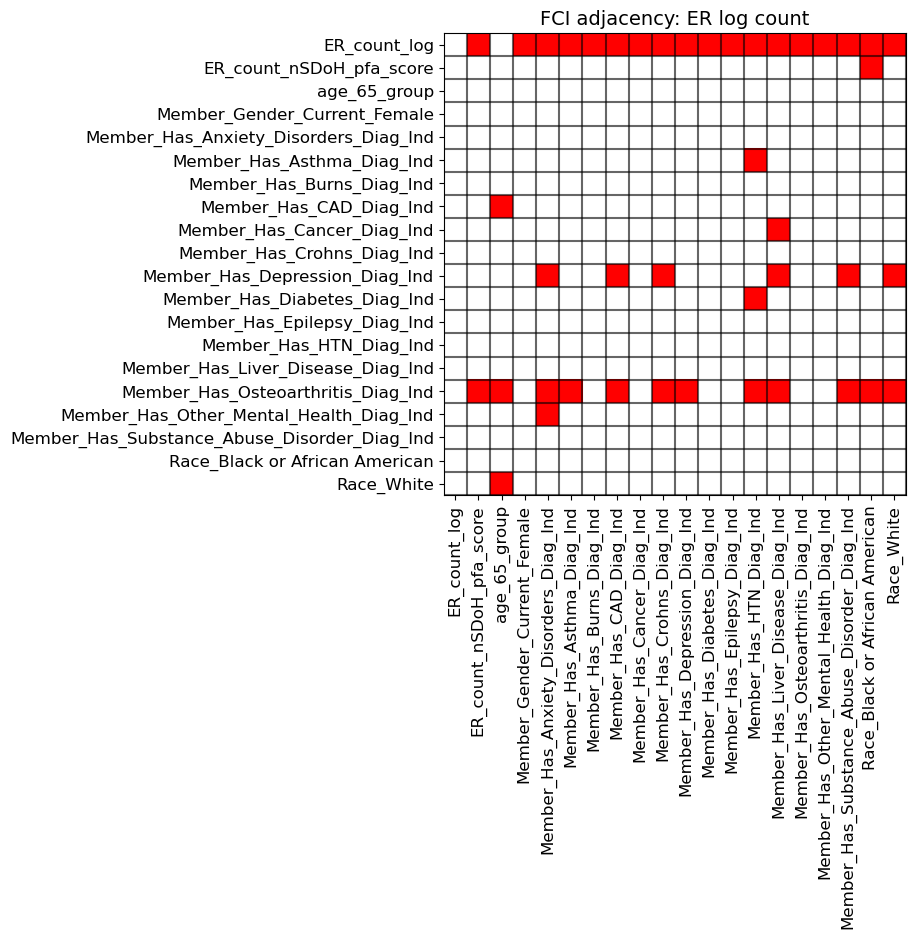

In [28]:
cmap = colors.ListedColormap(["white", "red"])

data_color = A.values

fig, ax = plt.subplots(figsize=(8, 6))

ax.imshow(data_color, cmap=cmap, vmin=0, vmax=1)

plt.xticks(
    np.arange(0, p, 1),
    list(A.columns),
    rotation=90,
    fontsize=12
)

plt.yticks(
    np.arange(0, p, 1),
    list(A.index),
    fontsize=12
)

# gridlines
x_cords = np.arange(0.5, p - 0.5 + 1e-9, 1)
y_cords = np.arange(0.5, p - 0.5 + 1e-9, 1)

for x_ in x_cords:
    plt.axvline(x=x_, color="black", alpha=0.6)

for y_ in y_cords:
    plt.axhline(y=y_, color="black", alpha=0.6)

plt.title("FCI adjacency: ER log count", fontsize=14)

# plt.savefig(
#     "../results/poisson_intensity_sample/fci_er_count_log_nsdoh85_adjacency.png",
#     dpi=300,
#     bbox_inches="tight"
# )

plt.show()

In [29]:
operator_map = {
    "-->": (Endpoint.TAIL, Endpoint.ARROW),
    "<--": (Endpoint.ARROW, Endpoint.TAIL),
    "o->": (Endpoint.CIRCLE, Endpoint.ARROW),
    "<-o": (Endpoint.ARROW, Endpoint.CIRCLE),
#    "o-o": (Endpoint.CIRCLE, Endpoint.CIRCLE),
#    "<->": (Endpoint.ARROW, Endpoint.ARROW),
#    "---": (Endpoint.TAIL, Endpoint.TAIL)
}

In [30]:
parsed_edges = []
all_node_names = set()

for edge_str in edges:
    
    for op_str, endpoints in operator_map.items():
        
        if op_str in edge_str:
            
            node1_name, node2_name = edge_str.split(op_str)
            
            node1_name = node1_name.strip()
            node2_name = node2_name.strip()
            
            parsed_edges.append(
                (
                    node1_name,
                    node2_name,
                    endpoints[0],
                    endpoints[1]
                )
            )
            
            all_node_names.add(node1_name)
            all_node_names.add(node2_name)
            
            break

nodes_graph = [GraphNode(name) for name in sorted(all_node_names)]

G = GeneralGraph(nodes_graph)

for node1_name, node2_name, endpoint1, endpoint2 in parsed_edges:
    
    node1 = G.get_node(node1_name)
    node2 = G.get_node(node2_name)
    
    new_edge = Edge(node1, node2, endpoint1, endpoint2)
    G.add_edge(new_edge)

print(f"Successfully reconstructed graph with {len(G.get_nodes())} nodes and {len(G.get_graph_edges())} edges.")

print("\nFirst 10 edges:")
for edge in G.get_graph_edges()[:10]:
    print(edge)

Successfully reconstructed graph with 20 nodes and 43 edges.

First 10 edges:
ER_count_nSDoH_pfa_score --> ER_count_log
Member_Gender_Current_Female --> ER_count_log
Member_Has_Anxiety_Disorders_Diag_Ind --> ER_count_log
Member_Has_Asthma_Diag_Ind --> ER_count_log
Member_Has_Burns_Diag_Ind --> ER_count_log
Member_Has_CAD_Diag_Ind --> ER_count_log
Member_Has_Cancer_Diag_Ind --> ER_count_log
Member_Has_Crohns_Diag_Ind --> ER_count_log
Member_Has_Depression_Diag_Ind --> ER_count_log
Member_Has_Diabetes_Diag_Ind --> ER_count_log


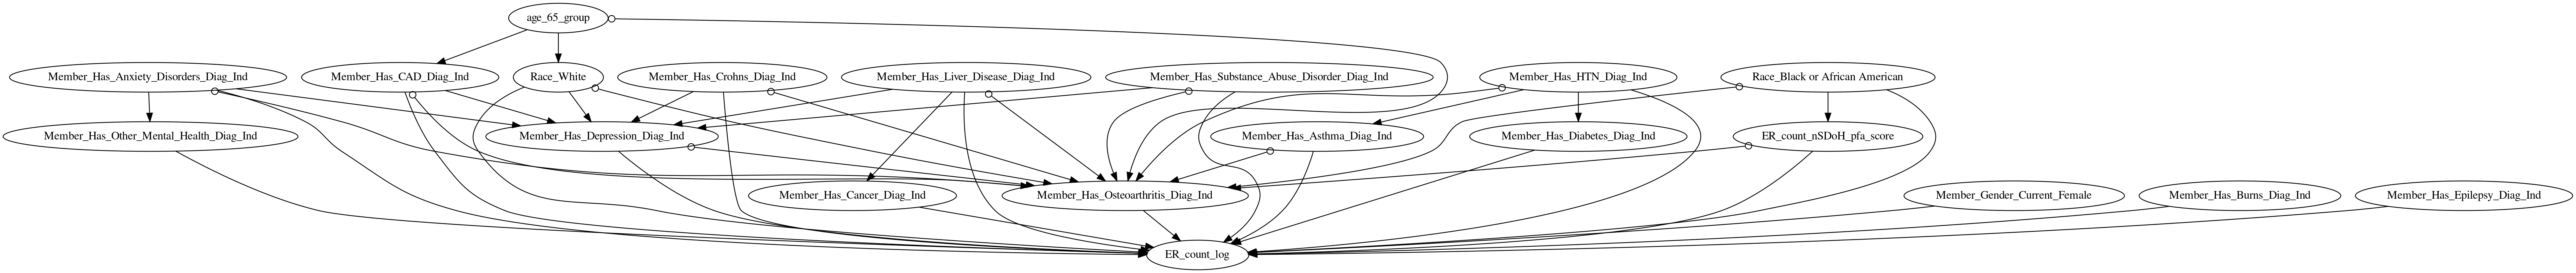

In [31]:
pydot_graph = GraphUtils.to_pydot(G)

pydot_graph.write_png(
    "../results/poisson_intensity_sample/fci_er_count_log_nsdohpfa_graph2.png"
)

display(Image(pydot_graph.create_png()))

In [23]:
freq_sub = fci_bootstrap_edges_with_bk(
    dat_pcp,
    outcome_name=Y,
    B=1,
    alpha=0.01,
    sample_frac=1.0,
    rng=np.random.default_rng(2025),
    ci_test=fisherz,
    show_progress=False
)

# freq_sub.to_csv(
#     "../results/poisson_intensity_sample/fci_er_count_log_nsdoh85_B50_alpha001.csv",
#     index=False
# )

freq_sub.head(30)

Rows available: 1476720
Bootstrap sample size per replicate: 1476720
Variables: 20
CI test: fisherz
Bootstrap replicate 1/1
Starting BK Orientation.
Orienting edge (Knowledge): ER_count_nSDoH_pfa_score --> ER_count_log
Orienting edge (Knowledge): Member_Has_HTN_Diag_Ind --> ER_count_log
Orienting edge (Knowledge): Member_Has_Asthma_Diag_Ind --> ER_count_log
Orienting edge (Knowledge): Member_Has_Anxiety_Disorders_Diag_Ind --> ER_count_log
Orienting edge (Knowledge): Member_Has_Substance_Abuse_Disorder_Diag_Ind --> ER_count_log
Orienting edge (Knowledge): Member_Has_Epilepsy_Diag_Ind --> ER_count_log
Orienting edge (Knowledge): Member_Has_Liver_Disease_Diag_Ind --> ER_count_log
Orienting edge (Knowledge): Member_Has_Burns_Diag_Ind --> ER_count_log
Orienting edge (Knowledge): Member_Has_Other_Mental_Health_Diag_Ind --> ER_count_log
Orienting edge (Knowledge): Member_Has_Cancer_Diag_Ind --> ER_count_log
Orienting edge (Knowledge): Member_Has_CAD_Diag_Ind --> ER_count_log
Orienting edge (K

,edge,count,freq
0,ER_count_nSDoH_pfa_score --> ER_count_log,1,1.0
1,Member_Has_HTN_Diag_Ind --> ER_count_log,1,1.0
2,Member_Has_Asthma_Diag_Ind --> ER_count_log,1,1.0
3,Member_Has_Anxiety_Disorders_Diag_Ind --> ER_c...,1,1.0
4,Member_Has_Substance_Abuse_Disorder_Diag_Ind -...,1,1.0
5,Member_Has_Epilepsy_Diag_Ind --> ER_count_log,1,1.0
6,Member_Has_Liver_Disease_Diag_Ind --> ER_count...,1,1.0
7,Member_Has_Burns_Diag_Ind --> ER_count_log,1,1.0
8,Member_Has_Other_Mental_Health_Diag_Ind --> ER...,1,1.0
9,Member_Has_Cancer_Diag_Ind --> ER_count_log,1,1.0


In [78]:
edges_dat = pd.read_csv(
    "../results/poisson_intensity_sample/fci_er_count_log_nsdoh85_B50_alpha001.csv"
)

MIN_FREQ = 0.30

edges_filtered = (
    edges_dat
    .loc[edges_dat["freq"] >= MIN_FREQ, "edge"]
    .dropna()
    .astype(str)
)

print("Original edges:", len(edges_dat))
print("Filtered edges:", len(edges_filtered))

edges_filtered.head(30)

Original edges: 232
Filtered edges: 76


0              Member_Has_HTN_Diag_Ind --> er_count_log
1         Race_Black or African American <-> Race_White
2     Member_Has_Substance_Abuse_Disorder_Diag_Ind -...
3     Member_Has_Depression_Diag_Ind <-> Member_Has_...
4     Member_Has_Cancer_Diag_Ind <-> Member_Has_Oste...
5     Member_Gender_Current_Female <-> Race_Black or...
6     Member_Has_Osteoarthritis_Diag_Ind <-> age_65_...
7                           Race_White <-> age_65_group
8     Member_Has_HTN_Diag_Ind <-> Race_Black or Afri...
9           Member_Has_Asthma_Diag_Ind --> er_count_log
10    Member_Has_CAD_Diag_Ind <-> Member_Has_HTN_Dia...
11    Member_Gender_Current_Female <-> Member_Has_CA...
12             Member_Has_CAD_Diag_Ind --> er_count_log
13    Member_Has_Osteoarthritis_Diag_Ind --> er_coun...
14    Member_Has_CAD_Diag_Ind <-> Member_Has_Cancer_...
15    Member_Has_Anxiety_Disorders_Diag_Ind <-> Memb...
16        Member_Has_Epilepsy_Diag_Ind --> er_count_log
17    Member_Has_CAD_Diag_Ind <-> Member_Has_Dia

In [79]:
focus_vars = ["er_count_log", "nsdoh_85_bin"]

edges_focus = edges_filtered[
    edges_filtered.apply(
        lambda s: any(v in s for v in focus_vars)
    )
]

print("Focused edges:", len(edges_focus))
edges_focus

Focused edges: 14


0              Member_Has_HTN_Diag_Ind --> er_count_log
2     Member_Has_Substance_Abuse_Disorder_Diag_Ind -...
9           Member_Has_Asthma_Diag_Ind --> er_count_log
12             Member_Has_CAD_Diag_Ind --> er_count_log
13    Member_Has_Osteoarthritis_Diag_Ind --> er_coun...
16        Member_Has_Epilepsy_Diag_Ind --> er_count_log
22                          Race_White <-> nsdoh_85_bin
24      Race_Black or African American <-> nsdoh_85_bin
27    Member_Has_Other_Mental_Health_Diag_Ind <-> ns...
28    Member_Has_Liver_Disease_Diag_Ind --> er_count...
51    Member_Has_Anxiety_Disorders_Diag_Ind --> er_c...
64                        age_65_group <-> nsdoh_85_bin
68             Member_Has_HTN_Diag_Ind <-> nsdoh_85_bin
72        Member_Gender_Current_Female <-> nsdoh_85_bin
Name: edge, dtype: object

Focused graph has 15 nodes and 14 edges.




In [80]:
operator_map = {
    "-->": (Endpoint.TAIL, Endpoint.ARROW),
    "<--": (Endpoint.ARROW, Endpoint.TAIL),
    "o->": (Endpoint.CIRCLE, Endpoint.ARROW),
    "<-o": (Endpoint.ARROW, Endpoint.CIRCLE),
    "o-o": (Endpoint.CIRCLE, Endpoint.CIRCLE),
    "<->": (Endpoint.ARROW, Endpoint.ARROW),
    "---": (Endpoint.TAIL, Endpoint.TAIL)
}

parsed_edges = []
all_node_names = set()

for edge_str in edges_focus:
    for op_str, endpoints in operator_map.items():
        if op_str in edge_str:
            node1_name, node2_name = edge_str.split(op_str)
            node1_name = node1_name.strip()
            node2_name = node2_name.strip()

            parsed_edges.append(
                (node1_name, node2_name, endpoints[0], endpoints[1])
            )

            all_node_names.add(node1_name)
            all_node_names.add(node2_name)
            break

nodes_graph = [GraphNode(name) for name in sorted(all_node_names)]
G_focus = GeneralGraph(nodes_graph)

for node1_name, node2_name, endpoint1, endpoint2 in parsed_edges:
    node1 = G_focus.get_node(node1_name)
    node2 = G_focus.get_node(node2_name)

    new_edge = Edge(node1, node2, endpoint1, endpoint2)
    G_focus.add_edge(new_edge)

print(
    f"Focused graph has {len(G_focus.get_nodes())} nodes and {len(G_focus.get_graph_edges())} edges."
)

pydot_graph = GraphUtils.to_pydot(G_focus)

# pydot_graph.write_png(
#     "../results/poisson_intensity_sample/fci_pcp_count_log_nsdoh85_focus_graph.png"
# )

display(Image(pydot_graph.create_png()))

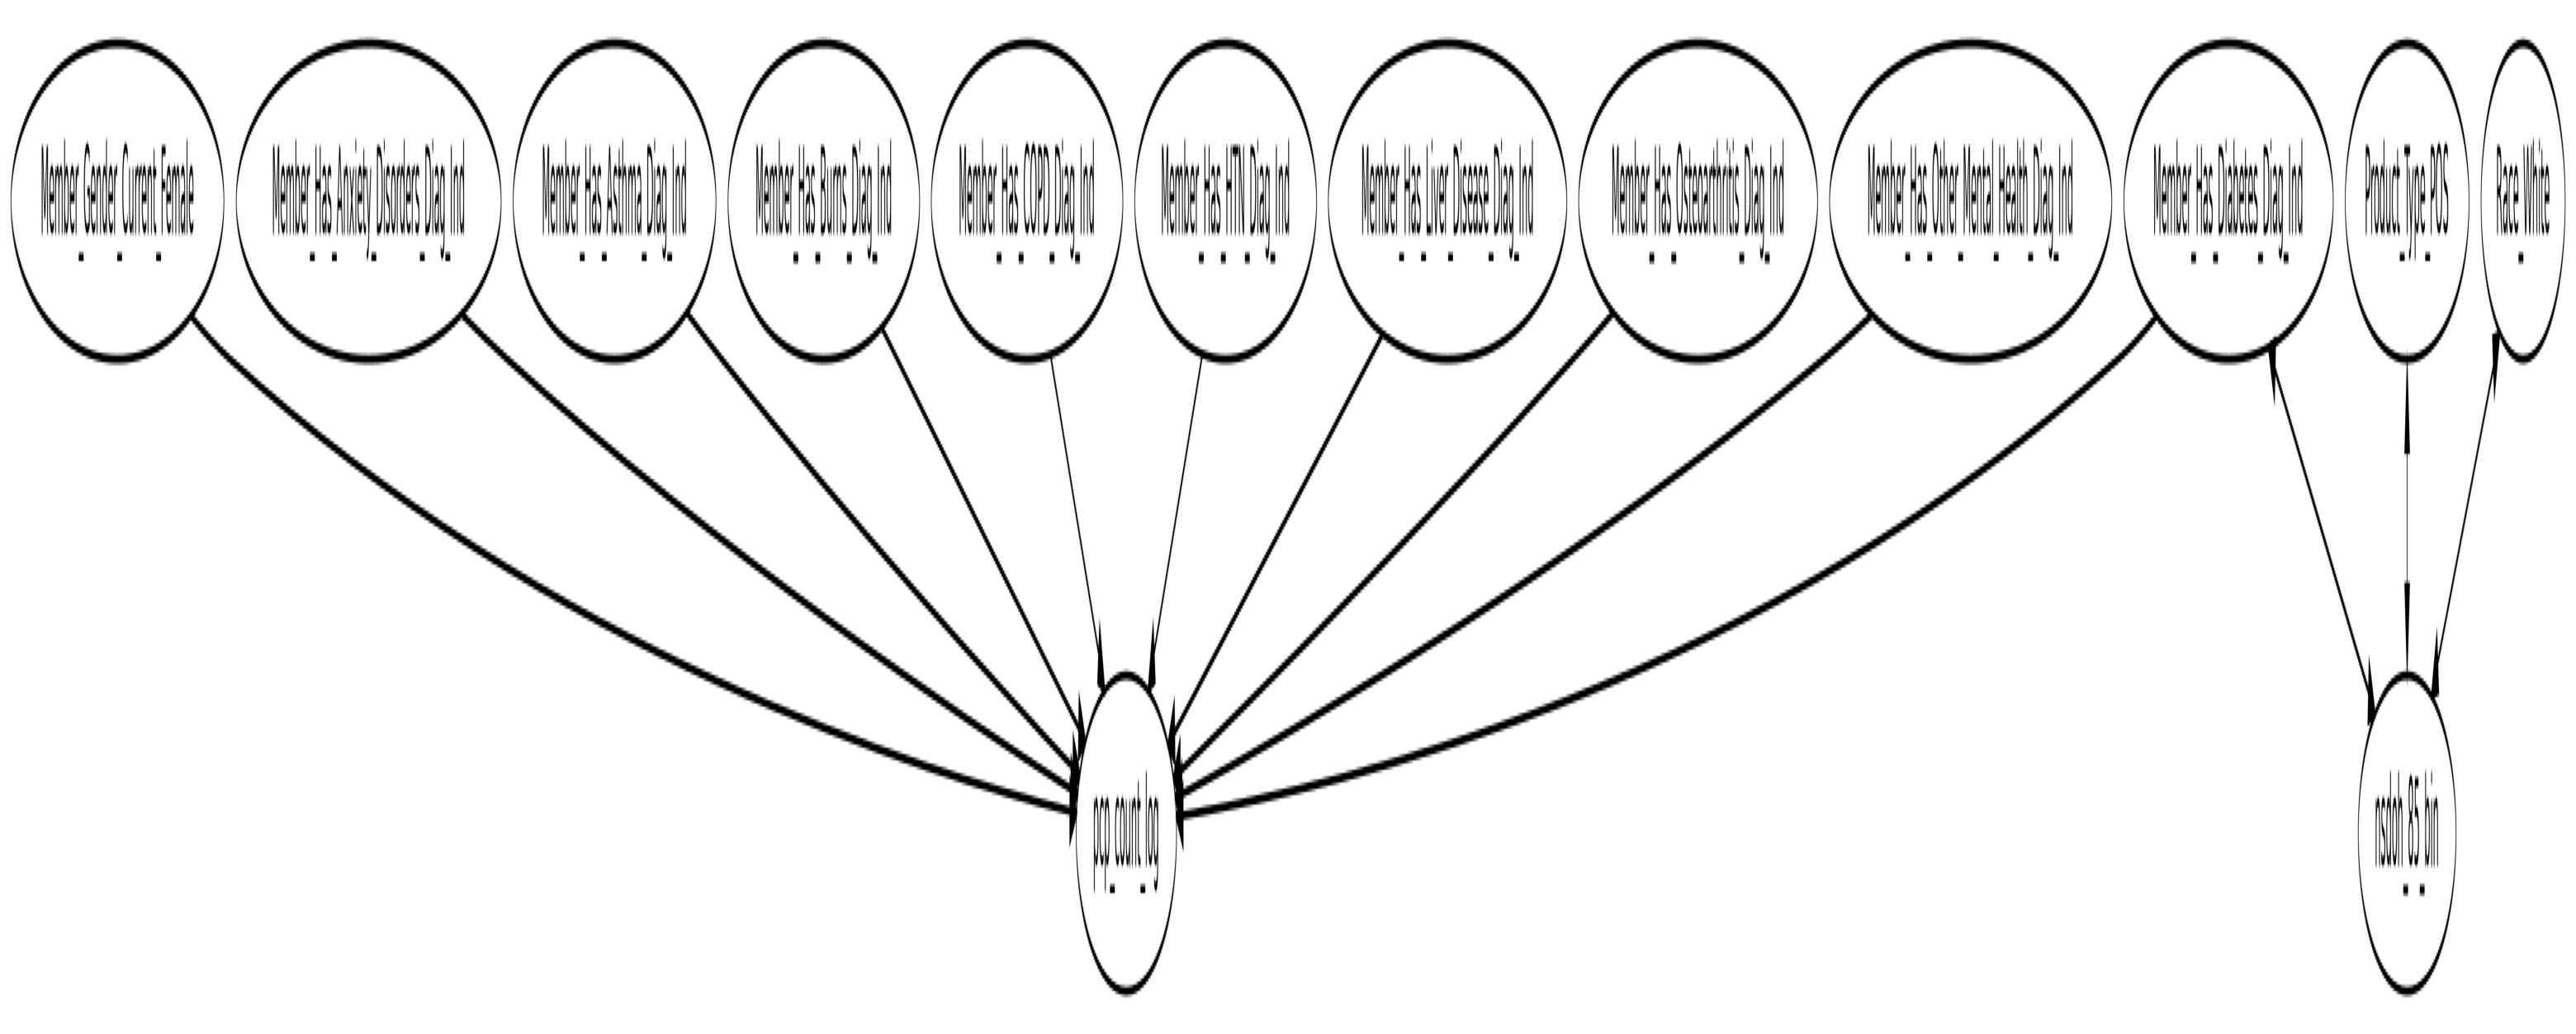

In [47]:
from io import BytesIO
from PIL import Image as PILImage
import matplotlib.pyplot as plt
img = PILImage.open(BytesIO(pydot_graph.create_png()))

plt.figure(figsize=(40, 16))   # increase second number to stretch vertically
plt.imshow(img, aspect="auto")
plt.axis("off")
plt.show()

In [53]:
from IPython.display import HTML, display
import base64

pydot_graph = GraphUtils.to_pydot(G_focus)

# Better rendering settings
pydot_graph.set("dpi", "120")
pydot_graph.set("ranksep", "0.8")
pydot_graph.set("nodesep", "0.4")
pydot_graph.set("pad", "0.3")
pydot_graph.set("margin", "0.2")

# Make node text readable without changing column names
for node in pydot_graph.get_nodes():
    node.set_fontsize("9")
    node.set_fontname("Arial")
    node.set_shape("box")
    node.set_margin("0.04,0.02")

for edge in pydot_graph.get_edges():
    edge.set_arrowsize("0.5")

# Save as SVG and PDF
#svg_path = "../results/poisson_intensity_sample/fci_pcp_count_log_nsdoh85_graph.svg"
#pdf_path = "../results/poisson_intensity_sample/fci_pcp_count_log_nsdoh85_graph.pdf"

#pydot_graph.write_svg(svg_path)
#pydot_graph.write_pdf(pdf_path)

# Display SVG in scrollable box
svg_data = pydot_graph.create_svg()
b64 = base64.b64encode(svg_data).decode("utf-8")

display(HTML(f"""
<div style="width:100%; overflow:auto; border:1px solid #ccc;">
    <img src="data:image/svg+xml;base64,{b64}" style="width:1100px;height:auto;">
</div>
"""))

In [81]:
from IPython.display import display
import os

pydot_graph = GraphUtils.to_pydot(G_focus)

# keep oval nodes
for node in pydot_graph.get_nodes():
    node.set_shape("ellipse")
    node.set_fontsize("10")
    node.set_fontname("Arial")

for edge in pydot_graph.get_edges():
    edge.set_arrowsize("0.6")

# save instead of forcing ugly notebook rendering
out_svg = "../results/poisson_intensity_sample/fci_er_graph.svg"
out_pdf = "../results/poisson_intensity_sample/fci_er_graph.pdf"
out_png = "../results/poisson_intensity_sample/fci_er_graph.png"

pydot_graph.write_svg(out_svg)
pydot_graph.write_pdf(out_pdf)
pydot_graph.write_png(out_png)

print("Saved SVG:", os.path.abspath(out_svg))
print("Saved PDF:", os.path.abspath(out_pdf))
print("Saved PNG:", os.path.abspath(out_png))

Saved SVG: /gpfs/data/chunaralab/swati/Insurance/results/poisson_intensity_sample/fci_er_graph.svg
Saved PDF: /gpfs/data/chunaralab/swati/Insurance/results/poisson_intensity_sample/fci_er_graph.pdf
Saved PNG: /gpfs/data/chunaralab/swati/Insurance/results/poisson_intensity_sample/fci_er_graph.png
